# 06 - Statistical Analysis & Business Insights

**Objective:** test the main descriptive findings formally, estimate the joint associations of weather and calendar factors with demand, and translate the results into operational implications.
**Grain:** `day.csv` for the tests and the regression (one observation per day); `hour.csv` for demand tiers.

### Method choices
- **Dependence:** consecutive days are autocorrelated, so classical p-values overstate certainty. Effect sizes come with **moving-block bootstrap CIs**, and the regression uses **Newey-West (HAC)** standard errors.
- **Distributions:** group variances differ, so the Welch t-test and Kruskal-Wallis are used, each with a parametric or non-parametric counterpart as a robustness check.
- **Interpretation:** associations only. Statistical significance is not treated as business importance.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore", message="findfont")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.visualization.style import apply_matplotlib_style
apply_matplotlib_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 40)
from src.analysis.results import compute_all
from src.analysis import stats as S
from src.visualization import figures as F
res = compute_all()

## Test 1 - Working vs non-working days

In [2]:
S.results_frame(res.working_tests)[['question', 'statistic', 'p_value', 'effect', 'ci_low', 'ci_high', 'note']]

,question,statistic,p_value,effect,ci_low,ci_high,note
0,Mean daily cnt: working vs non-working days,1.60,0.11,254.65,13.46,427.52,Mann-Whitney p = 0.119; rank-biserial r = 0.07...
1,Mean daily casual: working vs non-working days,-12.73,0.00,-764.56,-927.08,-661.21,Mann-Whitney p = 3.79e-29; rank-biserial r = -...
2,Mean daily registered: working vs non-working ...,9.24,0.00,"1,019.22",851.17,"1,164.29",Mann-Whitney p = 1.41e-16; rank-biserial r = 0...


- **Total demand:** small and inconclusive. Welch p is about 0.11, the block-bootstrap CI barely excludes zero, and d = 0.13, a negligible effect.
- **Casual demand:** much lower on working days (d of about -1.1, a large effect). **Registered demand:** higher (d of about 0.7).
- The opposite shifts largely cancel in the total. The useful finding is the change in composition, not in volume.

## Test 2 - Differences across seasons

In [3]:
print(res.season_test)
display(res.season_pairwise)

TestResult(question='Does daily cnt differ across seasons?', method='Kruskal-Wallis H (one-way ANOVA as robustness check); Holm-corrected Mann-Whitney post-hoc', statistic=250.9335046488973, p_value=4.110755793069794e-54, effect_name='Epsilon-squared (rank effect size)', effect=0.34103645756382023, ci_low=None, ci_high=None, n={'Winter': 181, 'Spring': 184, 'Summer': 188, 'Fall': 178}, note='ANOVA F = 128.8, p = 6.72e-67, eta² = 0.347; Levene p = 0.0214 (unequal variances -> rank test preferred)', extra={'anova_f': 128.76962156570778, 'anova_p': 6.720391362911461e-67, 'eta_sq': 0.3469916363256654, 'levene_p': 0.021385375904616144})


,season_a,season_b,median_a,median_b,p_raw,p_holm
0,Winter,Spring,"2,209.00","4,941.50",0.00,0.00
1,Winter,Summer,"2,209.00","5,353.50",0.00,0.00
2,Winter,Fall,"2,209.00","4,634.50",0.00,0.00
3,Spring,Summer,"4,941.50","5,353.50",0.00,0.00
4,Spring,Fall,"4,941.50","4,634.50",0.09,0.09
5,Summer,Fall,"5,353.50","4,634.50",0.00,0.00


Season has a large association with daily rentals (epsilon² of about 0.34). Every pair differs after Holm correction except Spring vs Fall.

## Model - Multivariable regression of daily rentals
Season, temperature and weather overlap, so a joint model isolates each one's association while holding the others fixed.

In [4]:
reg = res.regression
print(reg.formula)
print(f"n = {reg.nobs}, R² = {reg.r2:.3f}, adj. R² = {reg.adj_r2:.3f}, Durbin-Watson = {reg.durbin_watson:.2f}")
display(reg.coefficients)
display(reg.vif)
print(f"Fitted temperature effect peaks at {res.temp_turning_point:.1f} °C")

cnt ~ temp_ctr + I(temp_ctr ** 2) + hum_pct + windspeed_kmh + C(weather_group) + C(season_label) + C(year) + workingday
n = 730, R² = 0.849, adj. R² = 0.847, Durbin-Watson = 1.18


,coef,std_err_hac,p_value,ci_low,ci_high
Intercept,"5,223.40",301.85,0.00,"4,631.77","5,815.02"
C(weather_group)[T.Mist / cloudy],-396.75,74.20,0.00,-542.18,-251.31
C(weather_group)[T.Rain / snow],"-1,782.56",249.12,0.00,"-2,270.81","-1,294.30"
C(season_label)[T.Spring],869.16,165.45,0.00,544.87,"1,193.44"
C(season_label)[T.Summer],"1,066.26",213.36,0.00,648.08,"1,484.44"
C(season_label)[T.Fall],"1,203.03",160.62,0.00,888.22,"1,517.85"
C(year)[T.2012],"1,931.82",88.58,0.00,"1,758.21","2,105.43"
temp_ctr,111.89,11.46,0.00,89.42,134.36
I(temp_ctr ** 2),-7.80,1.35,0.00,-10.46,-5.15
hum_pct,-20.49,2.97,0.00,-26.30,-14.68


,term,vif
0,C(weather_group)[T.Mist / cloudy],1.65
1,C(weather_group)[T.Rain / snow],1.39
2,C(season_label)[T.Spring],2.77
3,C(season_label)[T.Summer],4.76
4,C(season_label)[T.Fall],2.06
5,C(year)[T.2012],1.05
6,temp_ctr,3.53
7,I(temp_ctr ** 2),1.52
8,hum_pct,2.13
9,windspeed_kmh,1.22


Fitted temperature effect peaks at 27.5 °C


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


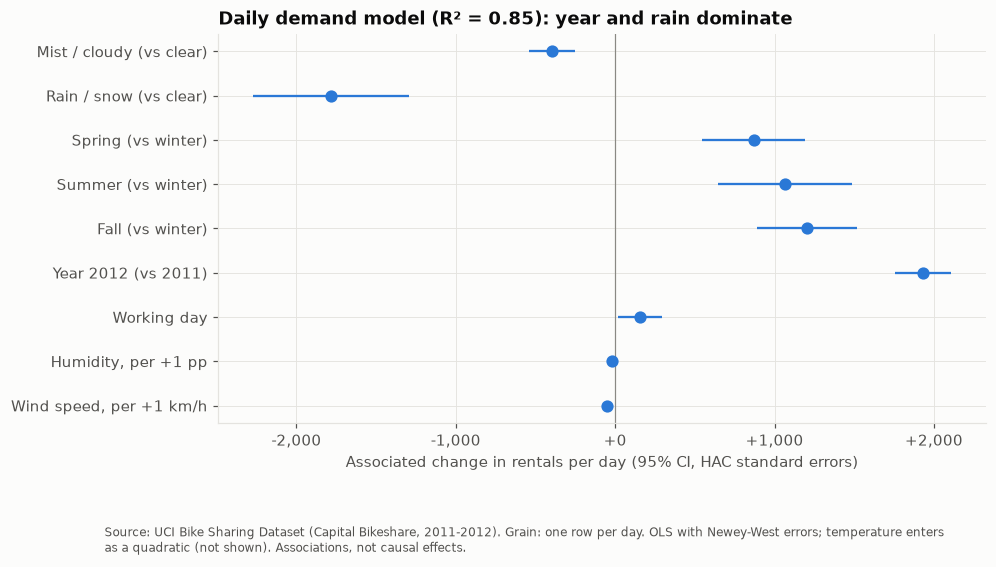

In [5]:
F.fig_regression(reg); plt.show()

**Diagnostics:** Durbin-Watson of about 1.18 indicates positive residual autocorrelation, which justifies the HAC errors. Temperature is centred, so all VIFs are below 5.

**Reading the model:** year (+1.9k per day), rain/snow (-1.8k per day) and season are the largest terms. Humidity and wind become clearly negative once temperature and season are held fixed. Winter stays lowest even at equal temperature, which may point to daylight or other unmeasured factors.

## Operational view - demand tiers (hourly grain)

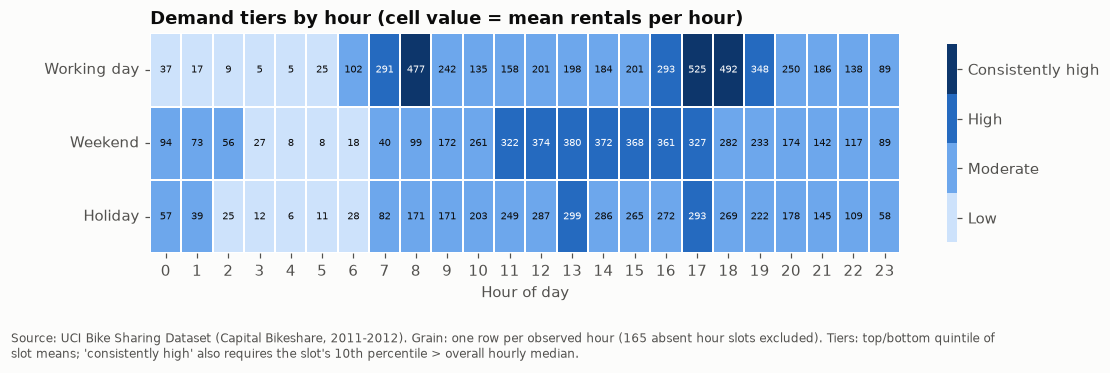

,day_type,hr,hours,mean_cnt,median_cnt,p10_cnt,p90_cnt,mean_casual,mean_registered,tier
0,Working day,0,496,36.79,33.00,12.00,65.00,7.15,29.64,Low
1,Working day,1,494,16.55,14.00,5.00,30.00,3.71,12.84,Low
2,Working day,2,487,8.68,7.00,2.00,16.40,2.14,6.55,Low
3,Working day,3,470,4.94,4.00,1.00,9.00,0.91,4.03,Low
4,Working day,4,470,5.43,5.00,1.00,10.00,0.77,4.66,Low
5,Working day,5,495,24.91,25.00,8.00,40.60,1.27,23.64,Low
8,Working day,8,496,477.01,463.00,210.50,719.00,22.26,454.74,Consistently high
17,Working day,17,499,525.29,539.00,195.60,844.20,56.90,468.39,Consistently high
18,Working day,18,498,492.23,504.50,171.40,811.30,50.45,441.78,Consistently high
27,Weekend,3,209,27.00,26.00,8.00,47.20,6.73,20.27,Low


In [6]:
F.fig_demand_windows(res.hour); plt.show()
display(res.windows.query('tier in ["Consistently high", "Low"]'))

## Business insights (implications, not measured outcomes)
| # | Finding | Evidence | Operational implication |
|---|---|---|---|
| 1 | Working-day 08:00 and 17:00-18:00 are the capacity-critical windows | Only slots classed as consistently high; mean of about 480-525 rentals per hour | Complete rebalancing before 07:00 and 16:00 on working days |
| 2 | Weekends are a casual-led leisure market | Casual share 32% vs 13%; midday plateau | Plan weekend capacity around 11:00-17:00; target casual riders for membership conversion |
| 3 | Overnight and winter are natural maintenance windows | 02:00-05:00 under about 60 rentals per hour on every day type; winter is about half of summer demand | Schedule routine maintenance overnight and overhauls in winter |
| 4 | Weather is a usable short-term signal | Rain/snow: -1.8k per day (HAC CI excludes 0) | Use forecasts to shift maintenance and staffing |
| 5 | Strong growth, fastest in January-March | +65% YoY | Review fleet and dock capacity against 2012 peaks |

## Limitations
- No station, inventory or maintenance data, so availability, stockouts and unmet demand cannot be measured.
- Two years only; the year term reflects growth that cannot be separated from network expansion.
- Observational data and serial dependence: all results are associations with somewhat optimistic precision.

The full narrative is in `reports/findings/Bike_Sharing_Report.docx`.